# Atividade computacional — Capítulo 6

**Aluno:** Kaynan Santos Freitas

## Preparação do ambiente

In [1]:
%pip install line_solver --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
from itertools import product
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.precision', 5)
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True

## Questão 1

O sistema possui duas classes fechadas: consultas (Q) e atualizações (U). Primeiro usamos as populações originais $N_Q=3$ e $N_U=1$. Depois triplicamos a população de atualizações, obtendo $N_U=3$.

In [3]:
recursos = ['CPU', 'Disco 1', 'Disco 2']
classes = ['Q', 'U']
D = np.array([
    [0.105, 0.375],
    [0.180, 0.480],
    [0.000, 0.240]
])

def resumo(D, N, Q, X, R):
    U = D * X
    por_classe = pd.DataFrame({
        'Classe': classes,
        'População': N,
        'Vazão': X,
        'Tempo de resposta': R.sum(axis=0)
    })
    por_recurso = pd.DataFrame({
        'Recurso': recursos,
        'Ocupação média': Q.sum(axis=1),
        'Utilização': U.sum(axis=1)
    })
    ocupacao = pd.DataFrame(Q, index=recursos, columns=classes)
    return por_classe, por_recurso, ocupacao

### MVA exato

O método exato percorre todos os estados populacionais. Para cada classe, aplica o teorema das chegadas ao estado que possui um cliente a menos daquela classe.

In [4]:
def mva_exato(D, N):
    N = np.array(N, dtype=int)
    m, c = D.shape
    ocupacoes = {tuple(np.zeros(c, dtype=int)): np.zeros((m, c))}
    estados = 0

    for estado in product(*[range(n + 1) for n in N]):
        if sum(estado) == 0:
            continue
        Q = np.zeros((m, c))
        for r in range(c):
            if estado[r] == 0:
                continue
            anterior = list(estado)
            anterior[r] -= 1
            Q_anterior = ocupacoes[tuple(anterior)]
            R_r = D[:, r] * (1 + Q_anterior.sum(axis=1))
            X_r = estado[r] / R_r.sum()
            Q[:, r] = X_r * R_r
        ocupacoes[estado] = Q
        estados += 1

    Q = ocupacoes[tuple(N)]
    R = np.zeros((m, c))
    X = np.zeros(c)
    for r in range(c):
        anterior = N.copy()
        anterior[r] -= 1
        R[:, r] = D[:, r] * (1 + ocupacoes[tuple(anterior)].sum(axis=1))
        X[r] = N[r] / R[:, r].sum()
    return Q, X, R, estados

### MVA aproximado

A aproximação estima o estado com um cliente a menos a partir das ocupações do estado completo. O processo termina quando a maior diferença entre duas estimativas sucessivas de $n_{i,r}$ é menor ou igual a 0,001.

In [5]:
def mva_aproximado(D, N, tolerancia=0.001, limite=10000):
    N = np.array(N, dtype=float)
    Q = D / D.sum(axis=0) * N

    for iteracao in range(1, limite + 1):
        R = np.zeros_like(D)
        X = np.zeros(len(N))
        novo_Q = np.zeros_like(D)

        for r in range(len(N)):
            fila_anterior = Q.sum(axis=1) - Q[:, r] / N[r]
            R[:, r] = D[:, r] * (1 + fila_anterior)
            X[r] = N[r] / R[:, r].sum()
            novo_Q[:, r] = X[r] * R[:, r]

        diferenca = np.max(np.abs(novo_Q - Q))
        Q = novo_Q
        if diferenca <= tolerancia:
            return Q, X, R, iteracao, diferenca

    raise RuntimeError('O método aproximado não convergiu')

In [6]:
def comparar_metodos(D, N):
    Qe, Xe, Re, estados = mva_exato(D, N)
    Qa, Xa, Ra, iteracoes, diferenca = mva_aproximado(D, N)
    tabela = pd.DataFrame({
        'Classe': classes,
        'X exato': Xe,
        'X aproximado': Xa,
        'Erro X (%)': 100 * np.abs(Xa - Xe) / Xe,
        'R exato': Re.sum(axis=0),
        'R aproximado': Ra.sum(axis=0),
        'Erro R (%)': 100 * np.abs(Ra.sum(axis=0) - Re.sum(axis=0)) / Re.sum(axis=0)
    })
    esforco = pd.DataFrame({
        'Método': ['Exato', 'Aproximado'],
        'Estados ou iterações': [estados, iteracoes]
    })
    return tabela, esforco, (Qe, Xe, Re), (Qa, Xa, Ra), diferenca

In [7]:
comparacao_original, esforco_original, exato_original, aproximado_original, diferenca_original = comparar_metodos(D, [3, 1])
comparacao_triplicada, esforco_triplicado, exato_triplicado, aproximado_triplicado, diferenca_triplicada = comparar_metodos(D, [3, 3])

print('Cenário original: N = (3, 1)')
display(comparacao_original)
display(esforco_original)
print(f'Diferença final: {diferenca_original:.6f}')

print('Cenário com atualizações triplicadas: N = (3, 3)')
display(comparacao_triplicada)
display(esforco_triplicado)
print(f'Diferença final: {diferenca_triplicada:.6f}')

Cenário original: N = (3, 1)


,Classe,X exato,X aproximado,Erro X (%),R exato,R aproximado,Erro R (%)
0,Q,4.09389,3.99688,2.36962,0.7328,0.75059,2.42713
1,U,0.40933,0.40692,0.58871,2.4430,2.45747,0.59220


,Método,Estados ou iterações
0,Exato,7
1,Aproximado,9


Diferença final: 0.000716
Cenário com atualizações triplicadas: N = (3, 3)


,Classe,X exato,X aproximado,Erro X (%),R exato,R aproximado,Erro R (%)
0,Q,2.93810,2.84614,3.12966,1.02107,1.05406,3.23077
1,U,0.90645,0.89889,0.83337,3.30963,3.33744,0.84037


,Método,Estados ou iterações
0,Exato,15
1,Aproximado,12


Diferença final: 0.000671


In [8]:
def medir_tempo(funcao, repeticoes=1000):
    inicio = perf_counter()
    for _ in range(repeticoes):
        funcao()
    return 1000 * (perf_counter() - inicio) / repeticoes

tempos = pd.DataFrame({
    'Cenário': ['Original', 'Original', 'Atualizações triplicadas', 'Atualizações triplicadas'],
    'Método': ['Exato', 'Aproximado', 'Exato', 'Aproximado'],
    'Tempo médio (ms)': [
        medir_tempo(lambda: mva_exato(D, [3, 1])),
        medir_tempo(lambda: mva_aproximado(D, [3, 1])),
        medir_tempo(lambda: mva_exato(D, [3, 3])),
        medir_tempo(lambda: mva_aproximado(D, [3, 3]))
    ]
})
tempos

,Cenário,Método,Tempo médio (ms)
0,Original,Exato,0.11776
1,Original,Aproximado,0.30622
2,Atualizações triplicadas,Exato,0.23739
3,Atualizações triplicadas,Aproximado,0.39587


O MVA exato avalia todas as combinações das populações das classes. O aproximado trabalha apenas com o estado final e repete os cálculos até atingir a tolerância. Ao triplicar as atualizações, a disputa pelos recursos aumenta e a diferença de custo entre os métodos fica mais visível.

## Questão 2

No modelo atual, consultas usam 0,180 s do Disco 1 e não usam o Disco 2. No cenário balanceado, essa demanda é dividida igualmente: 0,090 s em cada disco.

In [9]:
D_balanceado = D.copy()
D_balanceado[1, 0] = 0.090
D_balanceado[2, 0] = 0.090

def resultado_cenario(nome, D_cenario):
    Q, X, R, estados = mva_exato(D_cenario, [3, 1])
    _, recursos_cenario, _ = resumo(D_cenario, [3, 1], Q, X, R)
    return pd.DataFrame({
        'Cenário': nome,
        'Classe': classes,
        'Vazão': X,
        'Tempo de resposta': R.sum(axis=0)
    }), recursos_cenario

classes_atual, recursos_atual = resultado_cenario('Atual', D)
classes_balanceado, recursos_balanceado = resultado_cenario('Balanceado', D_balanceado)

display(pd.concat([classes_atual, classes_balanceado], ignore_index=True))

comparacao_recursos = recursos_atual.merge(recursos_balanceado, on='Recurso', suffixes=(' atual', ' balanceada'))
comparacao_recursos

,Cenário,Classe,Vazão,Tempo de resposta
0,Atual,Q,4.09389,0.73280
1,Atual,U,0.40933,2.44300
2,Balanceado,Q,5.24653,0.57181
3,Balanceado,U,0.45612,2.19241


,Recurso,Ocupação média atual,Utilização atual,Ocupação média balanceada,Utilização balanceada
0,CPU,1.12162,0.58336,1.5377,0.72193
1,Disco 1,2.78014,0.93338,1.4105,0.69112
2,Disco 2,0.09824,0.09824,1.0518,0.58166


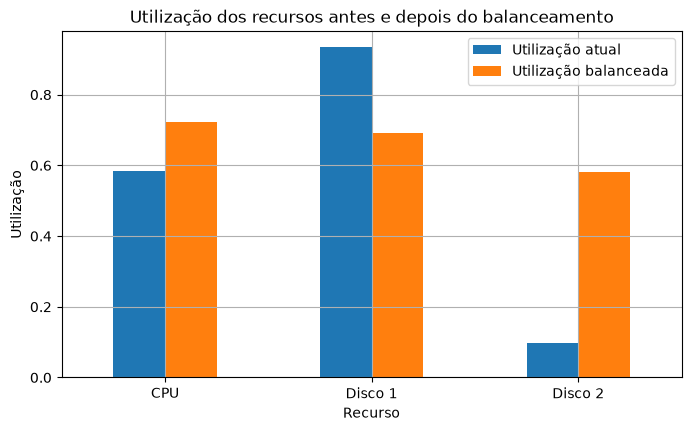

In [10]:
grafico = comparacao_recursos.set_index('Recurso')[['Utilização atual', 'Utilização balanceada']]
grafico.plot(kind='bar', rot=0)
plt.ylabel('Utilização')
plt.title('Utilização dos recursos antes e depois do balanceamento')
plt.show()

O balanceamento reduz a utilização do Disco 1 e aproveita a capacidade disponível do Disco 2. A comparação dos tempos de resposta e das vazões mostra o efeito dessa mudança sobre cada classe.

## Questão 3

As classes Q e U são abertas, com taxas de chegada conhecidas. A classe I é fechada e representa 50 usuários interativos com tempo de pensar de 15 segundos. Os valores de $N_r^{max}$ informados no enunciado são limites de multiprogramação. O modelo básico de rede de filas do LINE usado aqui representa diretamente as chegadas abertas e a população interativa, sem impor esses limites adicionais.

In [11]:
from line_solver import (
    ClosedClass, Delay, Exp, GlobalConstants, Network, OpenClass,
    Queue, SchedStrategy, Sink, SolverMVA, Source, VerboseLevel
)

GlobalConstants.set_verbose(VerboseLevel.SILENT)

D3 = {
    'CPU': {'Q': 0.060, 'U': 0.100, 'I': 0.090},
    'D1': {'Q': 0.030, 'U': 0.030, 'I': 0.045},
    'D2': {'Q': 0.060, 'U': 0.090, 'I': 0.000}
}

In [12]:
def resolver_line(lambda_q=3.0, terminais=50, fator_cpu=1.0, fator_d1=1.0):
    modelo = Network('Exercicio 3')
    fonte = Source(modelo, 'Fonte')
    cpu = Queue(modelo, 'CPU', SchedStrategy.FCFS)
    d1 = Queue(modelo, 'D1', SchedStrategy.FCFS)
    d2 = Queue(modelo, 'D2', SchedStrategy.FCFS)
    terminais_node = Delay(modelo, 'Terminais')
    saida = Sink(modelo, 'Saida')

    q = OpenClass(modelo, 'Q')
    u = OpenClass(modelo, 'U')
    i = ClosedClass(modelo, 'I', terminais, terminais_node)

    fonte.set_arrival(q, Exp(lambda_q))
    fonte.set_arrival(u, Exp(1.5))
    terminais_node.set_service(i, Exp(1 / 15))

    fatores = {'CPU': fator_cpu, 'D1': fator_d1, 'D2': 1.0}
    nodes = {'CPU': cpu, 'D1': d1, 'D2': d2}
    jobclasses = {'Q': q, 'U': u, 'I': i}

    for recurso, node in nodes.items():
        for classe, jobclass in jobclasses.items():
            demanda = D3[recurso][classe]
            if demanda > 0:
                node.set_service(jobclass, Exp(fatores[recurso] / demanda))

    rotas = modelo.init_routing_matrix()
    rotas.set(q, Network.serial_routing(fonte, cpu, d1, d2, saida))
    rotas.set(u, Network.serial_routing(fonte, cpu, d1, d2, saida))
    rotas.set(i, Network.serial_routing(terminais_node, cpu, d1, terminais_node))
    modelo.link(rotas)

    return SolverMVA(modelo).avg_table()

In [13]:
def tempos_resposta(tabela):
    filas = tabela[tabela['Station'].isin(['CPU', 'D1', 'D2'])]
    return filas.groupby('JobClass', as_index=False)['RespT'].sum().rename(columns={'JobClass': 'Classe', 'RespT': 'Tempo de resposta'})

def utilizacoes(tabela):
    filas = tabela[tabela['Station'].isin(['CPU', 'D1', 'D2'])]
    return filas.groupby('Station', as_index=False)['Util'].sum().rename(columns={'Station': 'Recurso', 'Util': 'Utilização'})

### (a) Tempos de resposta no cenário original

In [14]:
base = resolver_line()
display(tempos_resposta(base))
display(utilizacoes(base))

,Classe,Tempo de resposta
0,I,0.28650
1,Q,0.33651
2,U,0.40651


,Recurso,Utilização
0,CPU,0.62438
1,D1,0.28219
2,D2,0.31500


### (b) Aumento de 95% na chegada das consultas

A nova taxa é $3,0\times1,95=5,85$ transações por segundo.

In [15]:
aumento = resolver_line(lambda_q=5.85)
comparacao_b = tempos_resposta(base).merge(tempos_resposta(aumento), on='Classe', suffixes=(' original', ' com aumento'))
comparacao_b['Variação (%)'] = 100 * (comparacao_b['Tempo de resposta com aumento'] / comparacao_b['Tempo de resposta original'] - 1)
display(comparacao_b)
display(utilizacoes(aumento))

,Classe,Tempo de resposta original,Tempo de resposta com aumento,Variação (%)
0,I,0.28650,0.44993,57.04752
1,Q,0.33651,0.53198,58.08582
2,U,0.40651,0.60198,48.08360


,Recurso,Utilização
0,CPU,0.79226
1,D1,0.36613
2,D2,0.48600


### (c) Comparação dos upgrades

Um recurso duas vezes mais rápido possui metade da demanda de serviço.

In [16]:
cenarios = {
    'Sem upgrade': resolver_line(lambda_q=5.85),
    'D1 duas vezes mais rápido': resolver_line(lambda_q=5.85, fator_d1=2.0),
    'CPU duas vezes mais rápida': resolver_line(lambda_q=5.85, fator_cpu=2.0)
}

resultado_c = []
for nome, tabela in cenarios.items():
    parte = tempos_resposta(tabela)
    parte.insert(0, 'Cenário', nome)
    resultado_c.append(parte)

pd.concat(resultado_c, ignore_index=True)

,Cenário,Classe,Tempo de resposta
0,Sem upgrade,I,0.44993
1,Sem upgrade,Q,0.53198
2,Sem upgrade,U,0.60198
3,D1 duas vezes mais rápido,I,0.41218
4,D1 duas vezes mais rápido,Q,0.50158
5,D1 duas vezes mais rápido,U,0.57158
6,CPU duas vezes mais rápida,I,0.13672
7,CPU duas vezes mais rápida,Q,0.23174
8,CPU duas vezes mais rápida,U,0.28174


### (d) Número máximo de terminais

Mantemos a taxa de consultas aumentada e a CPU duas vezes mais rápida. O maior número aceitável de terminais deve manter o tempo de resposta da classe I abaixo de 15 segundos.

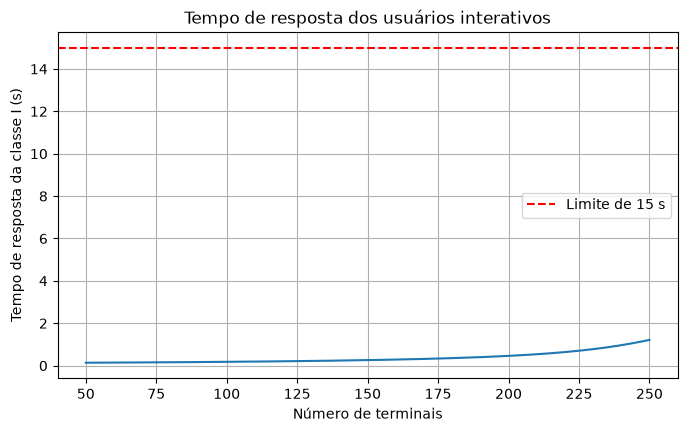

Maior número de terminais com resposta abaixo de 15 s: 250


In [17]:
linhas = []
for quantidade in range(50, 251):
    tabela = resolver_line(lambda_q=5.85, terminais=quantidade, fator_cpu=2.0)
    respostas = tempos_resposta(tabela).set_index('Classe')['Tempo de resposta']
    linhas.append({'Terminais': quantidade, 'Tempo de resposta I': respostas['I']})

resultado_d = pd.DataFrame(linhas)
aceitaveis = resultado_d[resultado_d['Tempo de resposta I'] < 15]
maximo = int(aceitaveis['Terminais'].max()) if not aceitaveis.empty else None

plt.plot(resultado_d['Terminais'], resultado_d['Tempo de resposta I'])
plt.axhline(15, color='red', linestyle='--', label='Limite de 15 s')
plt.xlabel('Número de terminais')
plt.ylabel('Tempo de resposta da classe I (s)')
plt.title('Tempo de resposta dos usuários interativos')
plt.legend()
plt.show()

print(f'Maior número de terminais com resposta abaixo de 15 s: {maximo}')

## Conclusão

O MVA aproximado reduz o trabalho necessário para populações maiores, apresentando resultados próximos aos do método exato. O balanceamento de E/S diminui a concentração de carga no Disco 1. No terceiro modelo, as utilizações ajudam a identificar o recurso que mais se beneficia de uma atualização e o gráfico determina a quantidade máxima de terminais compatível com a meta de resposta.